# FDM expansion for Diffusive Equations

In [8]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
import sympy as sp
import numpy as np
import re as regex
from sympy.tensor.indexed import Indexed
from IPython.display import display, Math, Latex
%run ~/Desktop/Bazarin-R.L.M.-AcademicDocumentation/docs/source/modules/eq_funcs.ipynb

us = sp.symbols('u_{x}^{t}')
omega = sp.symbols(r'\omega')
omg1=1-omega
cs = sp.symbols('c_s')

In [77]:
def make_shift_symbols(prefix=r'T_{\Delta_{x}}', order=9, var='c', start=0):
    names = [f'{prefix}^{{{var}_{{{i}}}}}' for i in range(start, start + order)]
    return sp.symbols(names)
Txc = make_shift_symbols(order=18, var='c')   # list of SymPy symbols
# Txc

In [38]:
def auto_collect(expr, ul):
    symbols = set(ul.values()) & expr.free_symbols
    symbols = sorted(symbols, key=sp.default_sort_key)
    return sp.collect(expr, symbols)

In [78]:
# from itertools import combinations, combinations_with_replacement
# # ----Multi-index shift symbols with permutation deduplication------
# def make_perm_shift_symbols(prefix=r'T_{\Delta_{x}}',
#                             order=9,
#                             var='c',
#                             start=0,
#                             length=2,
#                             include_repeats=False,
#                             canonical=True):
#     indices = range(start, start + order)
#     if include_repeats:
#         combos = combinations_with_replacement(indices, length)
#     else:
#         combos = combinations(indices, length)
#     out = {}
#     for combo in combos:
#         key = tuple(sorted(combo)) if canonical else tuple(combo)
#         sup = ''.join(f'{var}_{{{i}}}' for i in key)
#         out[key] = sp.Symbol(fr'{prefix}^{{{sup}}}')
#     return out

In [79]:
# p2T = make_perm_shift_symbols(order=7, length=2, include_repeats=False)
# # print(p2T[(0, 1)])   # T_{\Delta_{x}}^{c_{0}c_{1}}
# print(len(p2T))      # 36

In [80]:
# p3T = make_perm_shift_symbols(order=7, length=3, include_repeats=False)
# # print(p2T[(0,1,2)])   # T_{\Delta_{x}}^{c_{0}c_{1}}
# print(len(p3T))      # 36

In [81]:
def wheigt_symbols(prefix=r'w', order=9, start=0):
    names = [f'{prefix}_{{{i}}}' for i in range(start, start + order)]
    return sp.symbols(names)
w = wheigt_symbols(order=18)   # list of SymPy symbols
# w[0]

 ## One-Dimensional Cases: $D1Qq$ Lattices

In [4]:
import sympy as sp
ul = {}
past_steps = [1, 2, 3, 4, 5, 6,]
space_offsets = [1, 2, 3, 4, 5, 6]
# time_map: key_prefix -> (latex_expr): "+1" -> u^{t+1},  "0" -> u^{t},  "-1".."-4" -> u^{t-k}
time_map = {"+1": "t+1","0":  "t",**{f"-{k}": f"t-{k}" for k in past_steps},}

# Non-shifted symbols
for tk, te in time_map.items():
    ul[f"ut{tk}"] = sp.Symbol(fr'u^{{{te}}}_{{x}}')

# Shifted symbols (skip the future step "+1")
for tk, te in time_map.items():
    if tk == "+1":
        continue
    for ssign in ("+", "-"):
        for d in space_offsets:
            ul[f"ut{tk}d{ssign}{d}"] = sp.Symbol(fr'u^{{{te}}}_{{x{ssign}{d}}}')

In [5]:
# ul

### $D1Q3$

In [9]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
from sympy import *
import numpy as np
q=3
cx=np.array([0,1,-1])
wis=np.array([w[0],w[1],w[2]])
feq = us*wis

In [10]:
# OrderT = Matrix([0, 0, 0])
# # First order (single index)
# for i0 in range(q):
#     OrderT[0] = OrderT[0] + omega * feq[i0] * Txc[i0] + (1 - omega) * Txc[i0] * us
#     # Second order (unordered pairs i0 < i1)
#     for i1 in range(i0 + 1, q):
#         OrderT[1] = OrderT[1] + omega*(feq[i1]+feq[i0]) * Txc[i0]*Txc[i1] + (1-omega)*Txc[i0]*Txc[i1]*us
#         # Third order (unordered triples i0 < i1 < i2)
#         for i2 in range(i1 + 1, q):
#             OrderT[2] = OrderT[2] + omega*(feq[i2]+feq[i1]+feq[i0]) *Txc[i0]*Txc[i1]*Txc[i2] + (1-omega)*Txc[i0]*Txc[i1]*Txc[i2]*us

In [11]:
from itertools import combinations
import sympy as sp

OrderT = sp.Matrix([
    sum(
        (-omg1)**(n-1)
        * sp.prod(Txc[i] for i in idx)
        * (omega * sum(feq[i] for i in idx) + (1-omega)*us)
        for idx in combinations(range(q), n)
    )
    for n in range(1, 4)
])

In [12]:
# display(OrderT[0])
mt0=sp.collect(sp.expand(OrderT[0])
           .subs({Txc[1]*Txc[2]:1,Txc[0]:1})
           .subs(Txc[1]*us,ul['ut0d-1'])
           .subs(Txc[2]*us,ul['ut0d+1'])
           .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{us,ul['ut0d-1'],ul['ut0d+1']}
          )
display(mt0)

u^{t}_{x+1}*(1 - 5*\omega/6) + u^{t}_{x-1}*(1 - 5*\omega/6) + u_{x}^{t}*(1 - \omega/3)

In [13]:
# display(OrderT[1])
mt1=sp.collect(sp.expand(OrderT[1])
           .subs({Txc[1]*Txc[2]:1,Txc[0]:1})
           .subs(Txc[1]*us,ul['ut-1d-1'])
           .subs(Txc[2]*us,ul['ut-1d+1'])
           .subs(us,ul['ut-1'])
           .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-1'],ul['ut-1d-1'],ul['ut-1d+1']}
          )
display(mt1)

u^{t-1}_{x+1}*(-\omega**2/6 + 7*\omega/6 - 1) + u^{t-1}_{x-1}*(-\omega**2/6 + 7*\omega/6 - 1) + u^{t-1}_{x}*(-2*\omega**2/3 + 5*\omega/3 - 1)

In [14]:
mt2=sp.simplify(sp.expand(OrderT[2])
           .subs({Txc[1]*Txc[2]:1,Txc[0]:1})
           .subs({w[1]:Rational(1,6),w[2]:Rational(1,6),w[0]:Rational(2,3)})
           .subs(us,ul['ut-2'])
          )
display(mt2)

u^{t-2}_{x}*(\omega**2 - 2*\omega + 1)

In [15]:
# sp.Eq(ul['ut+1'],mt0+mt1+mt2)
display(Math(fdm_ordered_brokeq(sp.Eq(ul['ut+1'],mt0+mt1+mt2), terms_per_line=3, symbols=ul)))

<IPython.core.display.Math object>

### $D1Q5ZOT$

In [16]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
from sympy import *
import numpy as np
q=5
cx=np.array([0,1,-1,3,-3])
wis=np.array([w[0],w[1],w[2],w[3],w[4]])
w0 = sp.Rational(16, 45) + sp.Rational(4, 45)*sp.sqrt(10)
w1 = sp.Rational(3, 10) - sp.Rational(3, 80)*sp.sqrt(10)
w2 = sp.Rational(1, 45) - sp.Rational(1, 144)*sp.sqrt(10)
feq = us*wis

In [17]:
# OrderT = Matrix([0, 0, 0, 0, 0])
# # First order (single index)
# for i0 in range(q):
#     OrderT[0] = OrderT[0] + (-omg1)**(0)*(omega*feq[i0]*Txc[i0] + (1-omega)*Txc[i0]*us)
#     # Second order (unordered pairs i0 < i1)
#     for i1 in range(i0 + 1, q):
#         OrderT[1] = OrderT[1] + (-omg1)**(1)*(omega*(feq[i1]+feq[i0]) * Txc[i0]*Txc[i1] + (1-omega)*Txc[i0]*Txc[i1]*us)
#         # Third order (unordered triples i0 < i1 < i2)
#         for i2 in range(i1 + 1, q):
#             OrderT[2] = OrderT[2] + (-omg1)**(2)*(omega*(feq[i2]+feq[i1]+feq[i0]) *Txc[i0]*Txc[i1]*Txc[i2] + (1-omega)*Txc[i0]*Txc[i1]*Txc[i2]*us)
#             # Fourth order (unordered triples i0 < i1 < i2 < i3)
#             for i3 in range(i2 + 1, q):
#                 OrderT[3] = OrderT[3] + (-omg1)**(3)*(omega*(feq[i3]+feq[i2]+feq[i1]+feq[i0]) *Txc[i0]*Txc[i1]*Txc[i2]*Txc[i3] 
#                                          + (1-omega)*Txc[i0]*Txc[i1]*Txc[i2]*Txc[i3]*us)
#                 # Fiveth order (unordered triples i0 < i1 < i2 < i3 < i4)
#                 for i4 in range(i3 + 1, q):
#                     OrderT[4] = OrderT[4] + (-omg1)**(4)*(omega*(feq[i4]+feq[i3]+feq[i2]+feq[i1]+feq[i0]) *Txc[i0]*Txc[i1]*Txc[i2]*Txc[i3]*Txc[i4] 
#                                          + (1-omega)*Txc[i0]*Txc[i1]*Txc[i2]*Txc[i3]*Txc[i4]*us)

In [18]:
from itertools import combinations
import sympy as sp

OrderT = sp.Matrix([
    sum(
        (-omg1)**(n-1)
        * sp.prod(Txc[i] for i in idx)
        * (omega * sum(feq[i] for i in idx) + (1-omega)*us)
        for idx in combinations(range(q), n)
    )
    for n in range(1, 6)
])

In [19]:
# display(OrderT[0])
mt0=sp.collect(OrderT[0]
           .subs({Txc[1]*Txc[2]:1,Txc[0]:1})
           .subs(Txc[1]*us,ul['ut0d-1'])
           .subs(Txc[2]*us,ul['ut0d+1'])
           .subs(Txc[3]*us,ul['ut0d-3'])
           .subs(Txc[4]*us,ul['ut0d+3'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{us,ul['ut0d-1'],ul['ut0d+1'],ul['ut0d-3'],ul['ut0d+3']}
          )
display(mt0)

u_{x}^{t}*(T_{\Delta_{x}}^{c_{1}}*(\omega*w_{1} - \omega + 1) + T_{\Delta_{x}}^{c_{2}}*(\omega*w_{2} - \omega + 1) + T_{\Delta_{x}}^{c_{3}}*(\omega*w_{3} - \omega + 1) + T_{\Delta_{x}}^{c_{4}}*(\omega*w_{4} - \omega + 1) + \omega*w_{0} - \omega + 1)

In [20]:
# display(OrderT[1])
mt1=sp.collect(sp.expand(OrderT[1])
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[0]:1,
                  Txc[1]*Txc[3]:p2T[(1, 3)], Txc[2]*Txc[4]:p2T[(2, 4)], Txc[1]*Txc[4]:p2T[(1, 4)], Txc[2]*Txc[3]:p2T[(2, 3)]})
           .subs(Txc[1]*us,ul['ut-1d-1'])
           .subs(Txc[2]*us,ul['ut-1d+1'])
           .subs(Txc[3]*us,ul['ut-1d-3'])
           .subs(Txc[4]*us,ul['ut-1d+3'])        
           .subs(p2T[(1, 3)]*us,ul['ut-1d-4'])
           .subs(p2T[(2, 4)]*us,ul['ut-1d+4'])
           .subs(p2T[(1, 4)]*us,ul['ut-1d+2'])
           .subs(p2T[(2, 3)]*us,ul['ut-1d-2'])
           .subs(us,ul['ut-1'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-1'],ul['ut-1d-1'],ul['ut-1d+1'],ul['ut-1d-2'],ul['ut-1d+2'],ul['ut-1d-3'],ul['ut-1d+3'],ul['ut-1d-4'],ul['ut-1d+4']}
          )
# display(mt1)
brokeq2(mt1, terms_per_line=1)

<IPython.core.display.Math object>

In [21]:
# display(OrderT[2])
mt2=sp.collect(sp.expand(OrderT[2])
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:p2T[(1, 3)], Txc[2]*Txc[4]:p2T[(2, 4)], Txc[1]*Txc[4]:p2T[(1, 4)], Txc[2]*Txc[3]:p2T[(2, 3)]})
           .subs(Txc[1]*us,ul['ut-2d-1'])
           .subs(Txc[2]*us,ul['ut-2d+1'])
           .subs(Txc[3]*us,ul['ut-2d-3'])
           .subs(Txc[4]*us,ul['ut-2d+3'])        
           .subs(p2T[(1, 3)]*us,ul['ut-2d-4'])
           .subs(p2T[(2, 4)]*us,ul['ut-2d+4'])
           .subs(p2T[(1, 4)]*us,ul['ut-2d+2'])
           .subs(p2T[(2, 3)]*us,ul['ut-2d-2'])
           .subs(us,ul['ut-2'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-2'],ul['ut-2d-1'],ul['ut-2d+1'],ul['ut-2d-2'],ul['ut-2d+2'],ul['ut-2d-3'],ul['ut-2d+3'],ul['ut-2d-4'],ul['ut-2d+4']}
          )
# display(mt2)
brokeq2(mt2, terms_per_line=1)

<IPython.core.display.Math object>

In [22]:
# display(OrderT[3])
mt3=sp.collect(sp.expand(OrderT[3])
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:p2T[(1, 3)], Txc[2]*Txc[4]:p2T[(2, 4)], Txc[1]*Txc[4]:p2T[(1, 4)], Txc[2]*Txc[3]:p2T[(2, 3)]})
           .subs(Txc[1]*us,ul['ut-3d-1'])
           .subs(Txc[2]*us,ul['ut-3d+1'])
           .subs(Txc[3]*us,ul['ut-3d-3'])
           .subs(Txc[4]*us,ul['ut-3d+3'])        
           .subs(p2T[(1, 3)]*us,ul['ut-3d-4'])
           .subs(p2T[(2, 4)]*us,ul['ut-3d+4'])
           .subs(p2T[(1, 4)]*us,ul['ut-3d+2'])
           .subs(p2T[(2, 3)]*us,ul['ut-3d-2'])
           .subs(us,ul['ut-3'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-3'],ul['ut-3d-1'],ul['ut-3d+1'],ul['ut-3d-2'],ul['ut-3d+2'],ul['ut-3d-3'],ul['ut-3d+3'],ul['ut-3d-4'],ul['ut-3d+4']}
          )
# display(mt3)
brokeq2(mt3, terms_per_line=1)

<IPython.core.display.Math object>

In [23]:
# display(OrderT[4])
mt4=sp.collect(sp.expand(OrderT[4])
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:p2T[(1, 3)], Txc[2]*Txc[4]:p2T[(2, 4)], Txc[1]*Txc[4]:p2T[(1, 4)], Txc[2]*Txc[3]:p2T[(2, 3)]})
           .subs(Txc[1]*us,ul['ut-4d-1'])
           .subs(Txc[2]*us,ul['ut-4d+1'])
           .subs(Txc[3]*us,ul['ut-4d-3'])
           .subs(Txc[4]*us,ul['ut-4d+3'])        
           .subs(p2T[(1, 3)]*us,ul['ut-4d-4'])
           .subs(p2T[(2, 4)]*us,ul['ut-4d+4'])
           .subs(p2T[(1, 4)]*us,ul['ut-4d+2'])
           .subs(p2T[(2, 3)]*us,ul['ut-4d-2'])
           .subs(us,ul['ut-4'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-4'],ul['ut-4d-1'],ul['ut-4d+1'],ul['ut-4d-2'],ul['ut-4d+2'],ul['ut-4d-3'],ul['ut-4d+3'],ul['ut-4d-4'],ul['ut-4d+4']}
          )
# display(mt4)
brokeq2(mt4, terms_per_line=1)

<IPython.core.display.Math object>

In [24]:
# display_broken_equation(sp.Eq(ul['ut+1'],mt0+mt1+mt2+mt3+mt4), terms_per_line=1)
display(Math(fdm_ordered_brokeq(sp.Eq(ul['ut+1'],mt0+mt1+mt2+mt3+mt4), terms_per_line=1, symbols=ul)))

<IPython.core.display.Math object>

### $D1V7$

In [25]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
from sympy import *
import numpy as np
q=7
cx=np.array([0,1,-1,2,-2,3,-3])
wis=np.array([w[0],w[1],w[2],w[3],w[4],w[5],w[6]])
# w0 = sp.Rational(16, 45) + sp.Rational(4, 45)*sp.sqrt(10)
# w1 = sp.Rational(3, 10) - sp.Rational(3, 80)*sp.sqrt(10)
# w2 = sp.Rational(1, 45) - sp.Rational(1, 144)*sp.sqrt(10)
feq = us*wis

In [26]:
from itertools import combinations
import sympy as sp

OrderT = sp.Matrix([
    sum(
        (-omg1)**(n-1)
        * sp.prod(Txc[i] for i in idx)
        * (omega * sum(feq[i] for i in idx) + (1-omega)*us)
        for idx in combinations(range(q), n)
    )
    for n in range(1, 8)
])

In [27]:
# display(OrderT[0])
mt0=sp.collect(sp.expand(OrderT[0])
           .subs({Txc[1]*Txc[2]:1,Txc[0]:1})
           .subs(Txc[1]*us,ul['ut0d-1'])
           .subs(Txc[2]*us,ul['ut0d+1'])
           .subs(Txc[3]*us,ul['ut0d-2'])
           .subs(Txc[4]*us,ul['ut0d+2'])
           .subs(Txc[5]*us,ul['ut0d-3'])
           .subs(Txc[6]*us,ul['ut0d+3'])    
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{us,ul['ut0d-1'],ul['ut0d+1'],ul['ut0d-2'],ul['ut0d+2'],ul['ut0d-3'],ul['ut0d+3']}
          )
brokeq2(mt0, terms_per_line=1)

<IPython.core.display.Math object>

In [28]:
# display(OrderT[1])
mt1=sp.collect(sp.expand(OrderT[1])
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
           .subs(Txc[1]*us,ul['ut-1d-1'])
           .subs(Txc[2]*us,ul['ut-1d+1'])
           .subs(Txc[3]*us,ul['ut-1d-2'])
           .subs(Txc[4]*us,ul['ut-1d+2'])
           .subs(Txc[5]*us,ul['ut-1d-3'])
           .subs(Txc[6]*us,ul['ut-1d+3'])
           .subs(p2T[(1, 5)]*us,ul['ut-1d-4'])
           .subs(p2T[(2, 6)]*us,ul['ut-1d+4'])
           .subs(p2T[(3, 5)]*us,ul['ut-1d-5'])
           .subs(p2T[(4, 6)]*us,ul['ut-1d+5'])
           .subs(us,ul['ut-1'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-1'],ul['ut-1d-1'],ul['ut-1d+1'],ul['ut-1d-2'],ul['ut-1d+2'],ul['ut-1d-3'],ul['ut-1d+3'],ul['ut-1d-4'],ul['ut-1d+4']
            ,ul['ut-1d-5'],ul['ut-1d+5']}
          )
# display(mt1)
brokeq2(mt1, terms_per_line=1)

<IPython.core.display.Math object>

In [29]:
# display(OrderT[2])
mt2=sp.collect(sp.expand(OrderT[2])
           .subs({Txc[1]*Txc[3]*Txc[5]:p3T[(1,3,5)], Txc[2]*Txc[4]*Txc[6]:p3T[(2,4,6)]})
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
            .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
           .subs(Txc[1]*us,ul['ut-2d-1'])
           .subs(Txc[2]*us,ul['ut-2d+1'])
           .subs(Txc[3]*us,ul['ut-2d-2'])
           .subs(Txc[4]*us,ul['ut-2d+2'])
           .subs(Txc[5]*us,ul['ut-2d-3'])
           .subs(Txc[6]*us,ul['ut-2d+3'])
           .subs(p2T[(1, 5)]*us,ul['ut-2d-4'])
           .subs(p2T[(2, 6)]*us,ul['ut-2d+4'])
           .subs(p2T[(3, 5)]*us,ul['ut-2d-5'])
           .subs(p2T[(4, 6)]*us,ul['ut-2d+5'])
           .subs(p3T[(1,3,5)]*us,ul['ut-2d-6'])
           .subs(p3T[(2,4,6)]*us,ul['ut-2d+6'])
           .subs(us,ul['ut-2'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-2'],ul['ut-2d-1'],ul['ut-2d+1'],ul['ut-2d-2'],ul['ut-2d+2'],ul['ut-2d-3'],ul['ut-2d+3'],ul['ut-2d-4'],ul['ut-2d+4']
            ,ul['ut-2d-5'],ul['ut-2d+5'],ul['ut-2d-6'],ul['ut-2d+6']}
          )
# display(mt1)
brokeq2(mt2, terms_per_line=1)

<IPython.core.display.Math object>

In [30]:
# display(OrderT[3])
mt3=sp.collect(sp.expand(OrderT[3])
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]*Txc[5]:p3T[(1,3,5)], Txc[2]*Txc[4]*Txc[6]:p3T[(2,4,6)]})
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
            .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
           .subs(Txc[1]*us,ul['ut-3d-1'])
           .subs(Txc[2]*us,ul['ut-3d+1'])
           .subs(Txc[3]*us,ul['ut-3d-2'])
           .subs(Txc[4]*us,ul['ut-3d+2'])
           .subs(Txc[5]*us,ul['ut-3d-3'])
           .subs(Txc[6]*us,ul['ut-3d+3'])
           .subs(p2T[(1, 5)]*us,ul['ut-3d-4'])
           .subs(p2T[(2, 6)]*us,ul['ut-3d+4'])
           .subs(p2T[(3, 5)]*us,ul['ut-3d-5'])
           .subs(p2T[(4, 6)]*us,ul['ut-3d+5'])
           .subs(p3T[(1,3,5)]*us,ul['ut-3d-6'])
           .subs(p3T[(2,4,6)]*us,ul['ut-3d+6'])
           .subs(us,ul['ut-3'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-3'],ul['ut-3d-1'],ul['ut-3d+1'],ul['ut-3d-2'],ul['ut-3d+2'],ul['ut-3d-3'],ul['ut-3d+3'],ul['ut-3d-4'],ul['ut-3d+4']
            ,ul['ut-3d-5'],ul['ut-3d+5'],ul['ut-3d-6'],ul['ut-3d+6']}
          )
# display(mt3)
brokeq2(mt3, terms_per_line=1)

<IPython.core.display.Math object>

In [31]:
# display(OrderT[4])
mt4=sp.collect(sp.expand(OrderT[4])
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]*Txc[5]:p3T[(1,3,5)], Txc[2]*Txc[4]*Txc[6]:p3T[(2,4,6)]})
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
            .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
           .subs(Txc[1]*us,ul['ut-4d-1'])
           .subs(Txc[2]*us,ul['ut-4d+1'])
           .subs(Txc[3]*us,ul['ut-4d-2'])
           .subs(Txc[4]*us,ul['ut-4d+2'])
           .subs(Txc[5]*us,ul['ut-4d-3'])
           .subs(Txc[6]*us,ul['ut-4d+3'])
           .subs(p2T[(1, 5)]*us,ul['ut-4d-4'])
           .subs(p2T[(2, 6)]*us,ul['ut-4d+4'])
           .subs(p2T[(3, 5)]*us,ul['ut-4d-5'])
           .subs(p2T[(4, 6)]*us,ul['ut-4d+5'])
           .subs(p3T[(1,3,5)]*us,ul['ut-4d-6'])
           .subs(p3T[(2,4,6)]*us,ul['ut-4d+6'])
           .subs(us,ul['ut-4'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-4'],ul['ut-4d-1'],ul['ut-4d+1'],ul['ut-4d-2'],ul['ut-4d+2'],ul['ut-4d-3'],ul['ut-4d+3'],ul['ut-4d-4'],ul['ut-4d+4']
            ,ul['ut-4d-5'],ul['ut-4d+5'],ul['ut-4d-6'],ul['ut-4d+6']}
          )
# display(mt4)
brokeq2(mt4, terms_per_line=1)

<IPython.core.display.Math object>

In [32]:
# display(OrderT[5])
mt5=sp.collect(sp.expand(OrderT[5])
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]*Txc[5]:p3T[(1,3,5)], Txc[2]*Txc[4]*Txc[6]:p3T[(2,4,6)]})
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
            .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
           .subs(Txc[1]*us,ul['ut-5d-1'])
           .subs(Txc[2]*us,ul['ut-5d+1'])
           .subs(Txc[3]*us,ul['ut-5d-2'])
           .subs(Txc[4]*us,ul['ut-5d+2'])
           .subs(Txc[5]*us,ul['ut-5d-3'])
           .subs(Txc[6]*us,ul['ut-5d+3'])
           .subs(p2T[(1, 5)]*us,ul['ut-5d-4'])
           .subs(p2T[(2, 6)]*us,ul['ut-5d+4'])
           .subs(p2T[(3, 5)]*us,ul['ut-5d-5'])
           .subs(p2T[(4, 6)]*us,ul['ut-5d+5'])
           .subs(p3T[(1,3,5)]*us,ul['ut-5d-6'])
           .subs(p3T[(2,4,6)]*us,ul['ut-5d+6'])
           .subs(us,ul['ut-5'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-5'],ul['ut-5d-1'],ul['ut-5d+1'],ul['ut-5d-2'],ul['ut-5d+2'],ul['ut-5d-3'],ul['ut-5d+3'],ul['ut-5d-4'],ul['ut-5d+4']
            ,ul['ut-5d-5'],ul['ut-5d+5'],ul['ut-5d-6'],ul['ut-5d+6']}
          )
# display(mt5)
brokeq2(mt5, terms_per_line=1)

<IPython.core.display.Math object>

In [33]:
# display(OrderT[6])
mt6=sp.collect(sp.expand(OrderT[6])
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]*Txc[5]:p3T[(1,3,5)], Txc[2]*Txc[4]*Txc[6]:p3T[(2,4,6)]})
           .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
            .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[5]*Txc[6]:1, Txc[0]:1})
           .subs({Txc[1]*Txc[3]:Txc[5], Txc[2]*Txc[4]:Txc[6], Txc[1]*Txc[4]:Txc[2], Txc[2]*Txc[3]:Txc[1]})
           .subs({Txc[1]*Txc[5]:p2T[(1,5)], Txc[2]*Txc[6]:p2T[(2,6)], Txc[1]*Txc[6]:Txc[4], Txc[2]*Txc[5]:Txc[3]})
           .subs({Txc[3]*Txc[5]:p2T[(3,5)], Txc[4]*Txc[6]:p2T[(4,6)], Txc[3]*Txc[6]:Txc[2], Txc[4]*Txc[5]:Txc[1]})
           .subs(Txc[1]*us,ul['ut-6d-1'])
           .subs(Txc[2]*us,ul['ut-6d+1'])
           .subs(Txc[3]*us,ul['ut-6d-2'])
           .subs(Txc[4]*us,ul['ut-6d+2'])
           .subs(Txc[5]*us,ul['ut-6d-3'])
           .subs(Txc[6]*us,ul['ut-6d+3'])
           .subs(p2T[(1, 5)]*us,ul['ut-6d-4'])
           .subs(p2T[(2, 6)]*us,ul['ut-6d+4'])
           .subs(p2T[(3, 5)]*us,ul['ut-6d-5'])
           .subs(p2T[(4, 6)]*us,ul['ut-6d+5'])
           .subs(p3T[(1,3,5)]*us,ul['ut-6d-6'])
           .subs(p3T[(2,4,6)]*us,ul['ut-6d+6'])
           .subs(us,ul['ut-6'])
           # .subs({w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,3)})
           ,{ul['ut-6'],ul['ut-6d-1'],ul['ut-6d+1'],ul['ut-6d-2'],ul['ut-6d+2'],ul['ut-6d-3'],ul['ut-6d+3'],ul['ut-6d-4'],ul['ut-6d+4']
            ,ul['ut-6d-5'],ul['ut-6d+5'],ul['ut-6d-6'],ul['ut-6d+6']}
          )
# display(mt6)
brokeq2(mt6, terms_per_line=1)

<IPython.core.display.Math object>

In [34]:
display(Math(fdm_ordered_brokeq(sp.Eq(ul['ut+1'],mt0+mt1+mt2+mt3+mt4+mt5+mt6), terms_per_line=1, symbols=ul)))

<IPython.core.display.Math object>

 ## Two-Dimensional Cases: $D2Qq$ Lattices

In [14]:
import sympy as sp
#------------------Shift-Function-----------------------------------
def apply_velocity_shifts(expr, Txc, cx, cy, us, ul, time=-2):
    if len(cx) != len(cy) or len(cx) > len(Txc):
        raise ValueError("Incompatible lattice velocity arrays")
    velocities = [(int(x), int(y)) for x, y in zip(cx, cy)]
    operators = Txc[:len(velocities)]
    if expr.has(*Txc[len(velocities):]):
        raise ValueError("Some shift operators have undefined velocities")
    result = []
    # Expand into individual additive terms
    for term in sp.Add.make_args(sp.expand(expr)):
        powers = term.as_powers_dict()
        counts = [powers.get(op, 0) for op in operators]# Number of occurrences of each shift operator
        operator_factor = sp.prod(op**n for op, n in zip(operators, counts) ) # Extract operator product
        other = term / operator_factor
        # ------Case 1: Shift operators acting on us-----------
        if powers.get(us, 0) == 1:

            dx = -sum(int(n) * vx for n, (vx, vy) in zip(counts, velocities))
            dy = -sum(int(n) * vy for n, (vx, vy) in zip(counts, velocities) )

            # Build dictionary key
            key = f"ut{time}"
            if dx:
                key += f"dx{dx:+d}"
            if dy:
                key += f"dy{dy:+d}"
            # Generate missing symbols automatically
            if key not in ul:
                te = f"t{time:+d}" if time else "t"
                xp = f"x{dx:+d}" if dx else "x"
                yp = f"y{dy:+d}" if dy else "y"
                ul[key] = sp.Symbol(fr"u^{{{te}}}_{{{xp},{yp}}}")
            result.append((other / us) * ul[key])
        # ---Case 2: Simplify shift operators not acting on us---
        else:
            reduced = [int(n) for n in counts]
            for i, (vx, vy) in enumerate(velocities):
                # Zero-velocity operator is identity
                if vx == 0 and vy == 0:
                    reduced[i] = 0
                    continue
                # Cancel opposite shifts
                for j in range(i + 1, len(velocities)):
                    if velocities[j] == (-vx, -vy):
                        m = min(reduced[i], reduced[j])
                        reduced[i] -= m
                        reduced[j] -= m
            remaining = sp.prod(op**n for op, n in zip(operators, reduced))
            result.append(other * remaining)
    return sp.Add(*result)

In [17]:
import sympy as sp

ul = {}
past_steps = [1, 2, 3, 4, 5, 6]
space_offsets = [1, 2, 3, 4, 5, 6]
# Time mapping
time_map = {"+1": "t+1","0": "t",**{f"-{k}": f"t-{k}" for k in past_steps},}
# Non-shifted symbols
for tk, te in time_map.items():
    ul[f"ut{tk}"] = sp.Symbol(fr'u^{{{te}}}_{{x,y}}')
# Shifted symbols (skip future time "+1")
for tk, te in time_map.items():
    if tk == "+1":
        continue
    for ssign in ("+", "-"):
        for d in space_offsets:
            # Shift in x
            ul[f"ut{tk}dx{ssign}{d}"] = sp.Symbol(fr'u^{{{te}}}_{{x{ssign}{d},y}}')
            # Shift in y
            ul[f"ut{tk}dy{ssign}{d}"] = sp.Symbol(fr'u^{{{te}}}_{{x,y{ssign}{d}}}')
    # Simultaneous shifts in x and y
    for sx in ("+", "-"):
        for sy in ("+", "-"):
            for dx in space_offsets:
                for dy in space_offsets:
                    ul[f"ut{tk}dx{sx}{dx}dy{sy}{dy}"] = sp.Symbol(fr'u^{{{te}}}_{{x{sx}{dx},y{sy}{dy}}}')

In [18]:
# ul

### $D2Q5$

In [19]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
from sympy import *
import numpy as np
q=5
cx=np.array([0,1,-1,0,0])
cy=np.array([0,0,0,1,-1])
wis=np.array([w[0],w[1],w[2],w[3],w[4]])
feq = us*wis

In [20]:
from itertools import combinations
import sympy as sp

OrderT = sp.Matrix([
    sum(
        (-omg1)**(n-1)
        * sp.prod(Txc[i] for i in idx)
        * (omega * sum(feq[i] for i in idx) + (1-omega)*us)
        for idx in combinations(range(q), n)
    )
    for n in range(1, 6)
])

In [28]:
mt0_0=sp.expand(OrderT[0])
mt0_1 = apply_velocity_shifts(mt0_0, Txc, cx, cy, us, ul, time=0)
# display(mt0_1)
mt0 = sp.collect(mt0_1
        .subs({w[4]:Rational(1,6),w[3]:Rational(1,6),w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,6)})
           ,{ul['ut0'],ul['ut0dx-1'],ul['ut0dx+1'],ul['ut0dy-1'],ul['ut0dy+1']})
display(mt0)

u^{t}_{x+1,y}*(1 - 5*\omega/6) + u^{t}_{x,y+1}*(1 - 5*\omega/6) + u^{t}_{x,y-1}*(1 - 5*\omega/6) + u^{t}_{x,y}*(1 - 2*\omega/3) + u^{t}_{x-1,y}*(1 - 5*\omega/6)

In [26]:
# # display(OrderT[0])
# mt0=sp.collect(sp.expand(OrderT[0])
#            .subs({Txc[1]*Txc[2]:1,Txc[0]:1})
#            .subs(Txc[1]*us,ul['ut0dx-1'])
#            .subs(Txc[2]*us,ul['ut0dx+1'])
#            .subs(Txc[3]*us,ul['ut0dy-1'])
#            .subs(Txc[4]*us,ul['ut0dy+1'])
#            .subs({w[4]:Rational(1,6),w[3]:Rational(1,6),w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,6)})
#            ,{us,ul['ut0dx-1'],ul['ut0dx+1'],ul['ut0dy-1'],ul['ut0dy+1']}
#           )
# display(mt0)

In [34]:
mt1_0=sp.expand(OrderT[1])
mt1_1 = apply_velocity_shifts(mt1_0, Txc, cx, cy, us, ul, time=-1)
# display(mt1_1)
mt1 = sp.collect(mt1_1
        .subs({w[4]:Rational(1,6),w[3]:Rational(1,6),w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,6)})
           ,{ul['ut-1'],ul['ut-1dx-1'],ul['ut-1dx+1'],ul['ut-1dy-1'],ul['ut-1dy+1'],ul['ut-1dx-1dy-1'],ul['ut-1dx+1dy+1'],ul['ut-1dx-1dy+1'],ul['ut-1dx+1dy-1']})
brokeq2(mt1, terms_per_line=4)

<IPython.core.display.Math object>

In [33]:
# # display(OrderT[1])
# mt1=sp.collect(sp.expand(OrderT[1])
#            .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[0]:1,
#                   Txc[1]*Txc[3]:p2T[(1, 3)], Txc[2]*Txc[4]:p2T[(2, 4)], Txc[1]*Txc[4]:p2T[(1, 4)], Txc[2]*Txc[3]:p2T[(2, 3)]})
#            .subs(Txc[1]*us,ul['ut-1dx-1'])
#            .subs(Txc[2]*us,ul['ut-1dx+1'])
#            .subs(Txc[3]*us,ul['ut-1dy-1'])
#            .subs(Txc[4]*us,ul['ut-1dy+1'])        
#            .subs(p2T[(1, 3)]*us,ul['ut-1dx-1dy-1'])
#            .subs(p2T[(2, 4)]*us,ul['ut-1dx+1dy+1'])
#            .subs(p2T[(1, 4)]*us,ul['ut-1dx-1dy+1'])
#            .subs(p2T[(2, 3)]*us,ul['ut-1dx+1dy-1'])
#            .subs(us,ul['ut-1'])
#            .subs({w[4]:Rational(1,6),w[3]:Rational(1,6),w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,6)})
#            ,{ul['ut-1'],ul['ut-1dx-1'],ul['ut-1dx+1'],ul['ut-1dy-1'],ul['ut-1dy+1'],ul['ut-1dx-1dy-1'],ul['ut-1dx+1dy+1'],ul['ut-1dx-1dy+1'],ul['ut-1dx+1dy-1']}
#           )
# # display(mt1)
# brokeq2(mt1, terms_per_line=1)

In [40]:
mt2_0 = sp.expand(OrderT[2])
mt2_1 = apply_velocity_shifts(mt2_0, Txc, cx, cy, us, ul, time=-2)
weights = {w[0]: sp.Rational(2, 6),**{w[i]: sp.Rational(1, 6) for i in range(1, 5)} }
mt2 = auto_collect(mt2_1.subs(weights), ul)
brokeq2(mt2, terms_per_line=4)

<IPython.core.display.Math object>

In [37]:
# # display(OrderT[2])
# mt2=sp.collect(sp.expand(OrderT[2])
#            .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[0]:1})
#            .subs({Txc[1]*Txc[3]:p2T[(1, 3)], Txc[2]*Txc[4]:p2T[(2, 4)], Txc[1]*Txc[4]:p2T[(1, 4)], Txc[2]*Txc[3]:p2T[(2, 3)]})
#            .subs(Txc[1]*us,ul['ut-2dx-1'])
#            .subs(Txc[2]*us,ul['ut-2dx+1'])
#            .subs(Txc[3]*us,ul['ut-2dy-1'])
#            .subs(Txc[4]*us,ul['ut-2dy+1'])        
#            .subs(p2T[(1, 3)]*us,ul['ut-2dx-1dy-1'])
#            .subs(p2T[(2, 4)]*us,ul['ut-2dx+1dy+1'])
#            .subs(p2T[(1, 4)]*us,ul['ut-2dx-1dy+1'])
#            .subs(p2T[(2, 3)]*us,ul['ut-2dx+1dy-1'])
#            .subs(us,ul['ut-2'])
#            .subs({w[4]:Rational(1,6),w[3]:Rational(1,6),w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,6)})
#            ,{ul['ut-2'],ul['ut-2dx-1'],ul['ut-2dx+1'],ul['ut-2dy-1'],ul['ut-2dy+1'],ul['ut-2dx-1dy-1'],ul['ut-2dx+1dy+1'],ul['ut-2dx-1dy+1'],ul['ut-2dx+1dy-1']}
#           )
# # display(mt2)
# brokeq2(mt2, terms_per_line=1)

In [42]:
mt3_0 = sp.expand(OrderT[3])
mt3_1 = apply_velocity_shifts(mt3_0, Txc, cx, cy, us, ul, time=-3)
weights = {w[0]: sp.Rational(2, 6),**{w[i]: sp.Rational(1, 6) for i in range(1, 5)} }
mt3 = auto_collect(mt3_1.subs(weights), ul)
brokeq2(mt3, terms_per_line=4)

<IPython.core.display.Math object>

In [44]:
# # display(OrderT[3])
# mt3=sp.collect(sp.expand(OrderT[3])
#            .subs({Txc[1]*Txc[2]:1, Txc[3]*Txc[4]:1, Txc[0]:1})
#            .subs({Txc[1]*Txc[3]:p2T[(1, 3)], Txc[2]*Txc[4]:p2T[(2, 4)], Txc[1]*Txc[4]:p2T[(1, 4)], Txc[2]*Txc[3]:p2T[(2, 3)]})
#            .subs(Txc[1]*us,ul['ut-3dx-1'])
#            .subs(Txc[2]*us,ul['ut-3dx+1'])
#            .subs(Txc[3]*us,ul['ut-3dy-1'])
#            .subs(Txc[4]*us,ul['ut-3dy+1'])        
#            .subs(p2T[(1, 3)]*us,ul['ut-3dx-1dy-1'])
#            .subs(p2T[(2, 4)]*us,ul['ut-3dx+1dy+1'])
#            .subs(p2T[(1, 4)]*us,ul['ut-3dx-1dy+1'])
#            .subs(p2T[(2, 3)]*us,ul['ut-3dx+1dy-1'])
#            .subs(us,ul['ut-3'])
#            .subs({w[4]:Rational(1,6),w[3]:Rational(1,6),w[2]:Rational(1,6),w[1]:Rational(1,6),w[0]:Rational(2,6)})
#            ,{ul['ut-3'],ul['ut-3dx-1'],ul['ut-3dx+1'],ul['ut-3dy-1'],ul['ut-3dy+1'],ul['ut-3dx-1dy-1'],ul['ut-3dx+1dy+1'],ul['ut-3dx-1dy+1'],ul['ut-3dx+1dy-1']}
#           )
# # display(mt3)
# brokeq2(mt3, terms_per_line=4)

In [45]:
mt4_0 = sp.expand(OrderT[4])
mt4_1 = apply_velocity_shifts(mt4_0, Txc, cx, cy, us, ul, time=-4)
weights = {w[0]: sp.Rational(2, 6),**{w[i]: sp.Rational(1, 6) for i in range(1, 5)} }
mt4 = auto_collect(mt4_1.subs(weights), ul)
brokeq2(mt4, terms_per_line=4)

<IPython.core.display.Math object>

In [46]:
display(Math(fdm_ordered_brokeq(sp.Eq(ul['ut+1'],mt0+mt1+mt2+mt3+mt4), terms_per_line=4, symbols=ul)))

<IPython.core.display.Math object>

### $D2Q9$

In [47]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
from sympy import *
import numpy as np
q=9
cx=np.array([0, 1,-1, 0, 0, 1,-1,-1, 1])
cy=np.array([0, 0, 0, 1,-1, 1, 1,-1,-1])
wis=np.array([w[0],w[1],w[2],w[3],w[4],w[5],w[6],w[7],w[8]])
feq = us*wis

In [48]:
from itertools import combinations
import sympy as sp

OrderT = sp.Matrix([
    sum(
        (-omg1)**(n-1)
        * sp.prod(Txc[i] for i in idx)
        * (omega * sum(feq[i] for i in idx) + (1-omega)*us)
        for idx in combinations(range(q), n)
    )
    for n in range(1, 10)
])

In [53]:
mt0_0 = sp.expand(OrderT[0])
mt0_1 = apply_velocity_shifts(mt0_0, Txc, cx, cy, us, ul, time=0)
weights = {w[0]: sp.Rational(4, 9), w[1]: sp.Rational(1, 9), w[2]: sp.Rational(1, 9), w[3]: sp.Rational(1, 9), w[4]: sp.Rational(1, 9)
           ,w[5]: sp.Rational(1, 36), w[6]: sp.Rational(1, 36), w[7]: sp.Rational(1, 36), w[8]: sp.Rational(1, 36) }
mt0 = auto_collect(mt0_1.subs(weights), ul)
# mt0 = auto_collect(mt0_1, ul)
brokeq2(mt0, terms_per_line=4)

<IPython.core.display.Math object>

In [54]:
mt1_0 = sp.expand(OrderT[1])
mt1_1 = apply_velocity_shifts(mt1_0, Txc, cx, cy, us, ul, time=-1)
weights = {w[0]: sp.Rational(4, 9), w[1]: sp.Rational(1, 9), w[2]: sp.Rational(1, 9), w[3]: sp.Rational(1, 9), w[4]: sp.Rational(1, 9)
           ,w[5]: sp.Rational(1, 36), w[6]: sp.Rational(1, 36), w[7]: sp.Rational(1, 36), w[8]: sp.Rational(1, 36) }
mt1 = auto_collect(mt1_1.subs(weights), ul)
brokeq2(mt1, terms_per_line=4)

<IPython.core.display.Math object>

In [57]:
mt2_0 = sp.expand(OrderT[2])
mt2_1 = apply_velocity_shifts(mt2_0, Txc, cx, cy, us, ul, time=-2)
weights = {w[0]: sp.Rational(4, 9), w[1]: sp.Rational(1, 9), w[2]: sp.Rational(1, 9), w[3]: sp.Rational(1, 9), w[4]: sp.Rational(1, 9)
           ,w[5]: sp.Rational(1, 36), w[6]: sp.Rational(1, 36), w[7]: sp.Rational(1, 36), w[8]: sp.Rational(1, 36) }
mt2 = auto_collect(mt2_1.subs(weights), ul)
brokeq2(mt2, terms_per_line=4)

<IPython.core.display.Math object>

In [58]:
mt3_0 = sp.expand(OrderT[3])
mt3_1 = apply_velocity_shifts(mt3_0, Txc, cx, cy, us, ul, time=-3)
weights = {w[0]: sp.Rational(4, 9), w[1]: sp.Rational(1, 9), w[2]: sp.Rational(1, 9), w[3]: sp.Rational(1, 9), w[4]: sp.Rational(1, 9)
           ,w[5]: sp.Rational(1, 36), w[6]: sp.Rational(1, 36), w[7]: sp.Rational(1, 36), w[8]: sp.Rational(1, 36) }
mt3 = auto_collect(mt3_1.subs(weights), ul)
brokeq2(mt3, terms_per_line=4)

<IPython.core.display.Math object>

In [59]:
mt4_0 = sp.expand(OrderT[4])
mt4_1 = apply_velocity_shifts(mt4_0, Txc, cx, cy, us, ul, time=-4)
weights = {w[0]: sp.Rational(4, 9), w[1]: sp.Rational(1, 9), w[2]: sp.Rational(1, 9), w[3]: sp.Rational(1, 9), w[4]: sp.Rational(1, 9)
           ,w[5]: sp.Rational(1, 36), w[6]: sp.Rational(1, 36), w[7]: sp.Rational(1, 36), w[8]: sp.Rational(1, 36) }
mt4 = auto_collect(mt4_1.subs(weights), ul)
brokeq2(mt4, terms_per_line=4)

<IPython.core.display.Math object>

In [60]:
mt5_0 = sp.expand(OrderT[5])
mt5_1 = apply_velocity_shifts(mt5_0, Txc, cx, cy, us, ul, time=-5)
weights = {w[0]: sp.Rational(4, 9), w[1]: sp.Rational(1, 9), w[2]: sp.Rational(1, 9), w[3]: sp.Rational(1, 9), w[4]: sp.Rational(1, 9)
           ,w[5]: sp.Rational(1, 36), w[6]: sp.Rational(1, 36), w[7]: sp.Rational(1, 36), w[8]: sp.Rational(1, 36) }
mt5 = auto_collect(mt5_1.subs(weights), ul)
brokeq2(mt5, terms_per_line=4)

<IPython.core.display.Math object>

In [61]:
mt6_0 = sp.expand(OrderT[6])
mt6_1 = apply_velocity_shifts(mt6_0, Txc, cx, cy, us, ul, time=-6)
weights = {w[0]: sp.Rational(4, 9), w[1]: sp.Rational(1, 9), w[2]: sp.Rational(1, 9), w[3]: sp.Rational(1, 9), w[4]: sp.Rational(1, 9)
           ,w[5]: sp.Rational(1, 36), w[6]: sp.Rational(1, 36), w[7]: sp.Rational(1, 36), w[8]: sp.Rational(1, 36) }
mt6 = auto_collect(mt6_1.subs(weights), ul)
brokeq2(mt6, terms_per_line=4)

<IPython.core.display.Math object>

In [62]:
mt7_0 = sp.expand(OrderT[7])
mt7_1 = apply_velocity_shifts(mt7_0, Txc, cx, cy, us, ul, time=-7)
weights = {w[0]: sp.Rational(4, 9), w[1]: sp.Rational(1, 9), w[2]: sp.Rational(1, 9), w[3]: sp.Rational(1, 9), w[4]: sp.Rational(1, 9)
           ,w[5]: sp.Rational(1, 36), w[6]: sp.Rational(1, 36), w[7]: sp.Rational(1, 36), w[8]: sp.Rational(1, 36) }
mt7 = auto_collect(mt7_1.subs(weights), ul)
brokeq2(mt7, terms_per_line=4)

<IPython.core.display.Math object>

In [63]:
mt8_0 = sp.expand(OrderT[8])
mt8_1 = apply_velocity_shifts(mt8_0, Txc, cx, cy, us, ul, time=-8)
weights = {w[0]: sp.Rational(4, 9), w[1]: sp.Rational(1, 9), w[2]: sp.Rational(1, 9), w[3]: sp.Rational(1, 9), w[4]: sp.Rational(1, 9)
           ,w[5]: sp.Rational(1, 36), w[6]: sp.Rational(1, 36), w[7]: sp.Rational(1, 36), w[8]: sp.Rational(1, 36) }
mt8 = auto_collect(mt8_1.subs(weights), ul)
brokeq2(mt8, terms_per_line=4)

<IPython.core.display.Math object>

In [64]:
weights = {w[0]: sp.Rational(4, 9), **{w[i]: sp.Rational(1, 9) for i in range(1, 5)}, **{w[i]: sp.Rational(1, 36) for i in range(5, 9)} }
# Automatically process all orders
mt = {}
for i in range(len(OrderT)):
    expr = sp.expand(OrderT[i])
    expr = apply_velocity_shifts(expr, Txc, cx, cy, us, ul, time=-i)
    mt[i] = auto_collect(expr.subs(weights), ul)
    print(f"Order {i}:")
    brokeq2(mt[i], terms_per_line=4)

Order 0:


<IPython.core.display.Math object>

Order 1:


<IPython.core.display.Math object>

Order 2:


...

<IPython.core.display.Math object>

Order 7:


<IPython.core.display.Math object>

Order 8:


<IPython.core.display.Math object>

In [65]:
display(Math(fdm_ordered_brokeq(sp.Eq(ul['ut+1'],mt[0]+mt[1]+mt[2]+mt[3]+mt[4]+mt[5]+mt[6]+mt[7]+mt[8]), terms_per_line=4, symbols=ul)))

<IPython.core.display.Math object>

In [72]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import re

def plot_fdm_stencil(mt, ul, cx, cy, figsize=(7, 7)):
    # ----------------1. Identify Cartesian positions from ul symbols----------------------------------
    pattern = re.compile(r"^ut(?:\+1|0|-\d+)"r"(?:dx([+-]\d+))?"r"(?:dy([+-]\d+))?$")
    # Reverse mapping: SymPy symbol -> dictionary key
    symbol_to_key = {v: k for k, v in ul.items()}
    points_by_order = {}
    for i, expr in mt.items():
        points = set()
        for symbol in expr.free_symbols:
            key = symbol_to_key.get(symbol)
            if key is None:
                continue
            match = pattern.fullmatch(key)
            if match is None:
                continue
            dx = int(match.group(1) or 0)
            dy = int(match.group(2) or 0)
            points.add((dx, dy))
        points_by_order[i] = points
    # --------------------Union of all Cartesian points------------------------------
    all_points = set().union(*points_by_order.values())
    if not all_points:
        raise ValueError("No shifted spatial symbols found.")
    # Original lattice velocities
    base_points = {(-int(x), -int(y)) for x, y in zip(cx, cy)}
    # Only count points actually present in mt
    black_points = all_points & base_points
    red_points = all_points - base_points
    # --------------------Print stencil information------------------------------
    # for i, points in sorted(points_by_order.items()):
    #     print(f"mt[{i}]: {len(points)} Cartesian points")

    # print(f"\nOriginal lattice points: {len(black_points)}")
    # print(f"Additional points:       {len(red_points)}")
    # print(f"Total stencil points:    {len(all_points)}")
    # ---------------------4. Plot-----------------------------
    fig, ax = plt.subplots(figsize=figsize)
    if black_points:
        x, y = zip(*sorted(black_points))
        ax.scatter(x, y, color="black", s=100, zorder=3)
    if red_points:
        x, y = zip(*sorted(red_points))
        ax.scatter(x, y, color="red", s=100, zorder=3)
    xs, ys = zip(*all_points)
    ax.set_xticks(np.arange(min(xs), max(xs) + 1))
    ax.set_yticks(np.arange(min(ys), max(ys) + 1))
    ax.set_xlim(min(xs) - 0.5, max(xs) + 0.5)
    ax.set_ylim(min(ys) - 0.5, max(ys) + 0.5)
    ax.set_aspect("equal")
    ax.grid(True, color="lightgray", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.set_xlabel(r"$\Delta x$")
    ax.set_ylabel(r"$\Delta y$")
    ax.set_title(f"{len(all_points)}-point stencil " f"({len(black_points)} + {len(red_points)})" )
    plt.tight_layout()
    plt.show()
    return all_points, points_by_order

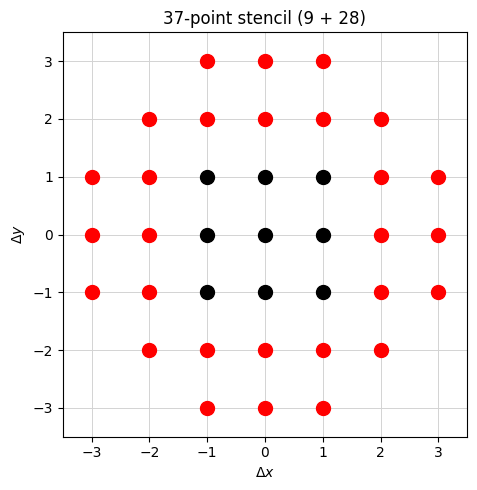

In [76]:
all_points, points_by_order = plot_fdm_stencil(mt, ul, cx, cy, figsize=(5, 5))

### $D2V17ZOT$

In [86]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
from sympy import *
import numpy as np
q=17
cx=np.array([0, 1,-1, 0, 0, 1,-1,-1, 1, 3,-3, 0, 0, 3,-3,-3, 3,])
cy=np.array([0, 0, 0, 1,-1, 1, 1,-1,-1, 0, 0, 3,-3, 3, 3,-3,-3,])
wis=np.array([w[i] for i in range(0, 18)])
feq = us*wis

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [ ]:
from itertools import combinations
import sympy as sp

OrderT = sp.Matrix([
    sum(
        (-omg1)**(n-1)
        * sp.prod(Txc[i] for i in idx)
        * (omega * sum(feq[i] for i in idx) + (1-omega)*us)
        for idx in combinations(range(q), n)
    )
    for n in range(1, q+1)
])

In [ ]:
# weights = {w[0]: sp.Rational(4, 9), **{w[i]: sp.Rational(1, 9) for i in range(1, 5)}, **{w[i]: sp.Rational(1, 36) for i in range(5, 9)} }
# Automatically process all orders
mt = {}
for i in range(len(OrderT)):
    expr = sp.expand(OrderT[i])
    expr = apply_velocity_shifts(expr, Txc, cx, cy, us, ul, time=-i)
    # mt[i] = auto_collect(expr.subs(weights), ul)
    mt[i] = auto_collect(expr, ul)
    print(f"Order {i}:")
    brokeq2(mt[i], terms_per_line=4)